# Tumor dynamics: a checked 2D proliferation–invasion model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/AI-assisted-glioma-research/blob/main/notebooks/02_tumor_dynamics.ipynb)

**Question:** What distinguishes migration, local proliferation and a changing imaging boundary,
and how can we verify a model before using real anatomy?
**Evidence:** Synthetic numerical experiments on a 1-mm grid: an isotropic disk (Figure 1) and
tissue-guided, anisotropic spread on a constructed coronal brain phantom (Figure 2), each with an
interactive explorer; analytic verification; and a scale comparison of the prescribed coefficients
with published patient-derived estimates.
Scientific functions live in `glioma_ai.growth_model`, `glioma_ai.tissue_growth`,
`glioma_ai.growth_examples` and `glioma_ai.growth_interactive`; this notebook exposes their
assumptions and interprets their outputs.
Run on CPU with the locked project environment documented in README.md. The sliders need a running
kernel with the `notebooks` dependency group (`make setup`); the static figures are produced
either way. In Google Colab, the first code cell clones the public repository and puts its package on the path; Colab's own NumPy, Matplotlib and nibabel are used, not the locked versions.

## Motivation: from observed boundaries to forecasts

**Observing a boundary.** On MRI a glioma is observed through a boundary, delineated either
manually by a neuroradiologist or automatically by a segmentation model. Both come with error:
readers disagree with each other and with themselves, models disagree with their reference labels
(notebook 01), and any boundary is a threshold on an underlying signal (Figure 1F below). The
observation can be made once, at diagnosis, or repeated over time. Between examinations the
outlined region may expand, shift, shrink after treatment, or split into spatially separate
(disjoint) regions, and the delineation is repeated at each visit. Even a careful series is
therefore a sparse, noisy sampling of a process that continues between and beyond the scans.

**Can growth be forecast?** The natural next question is whether tumor growth and evolution in
space and time can be modelled and predicted, much as weather is forecast from spatio-temporal
governing equations. Numerical weather prediction integrates well-established fluid-dynamical
equations from an initial state estimated by assimilating observations. For tumors the governing
equations are only partly known: the proliferation–invasion model used below is a hypothesis about
the dominant mechanisms, not a physical law. Yankeelov et al. proposed applying the methods of
weather forecasting, including data assimilation, to tumor growth and treatment response
([Cancer Res 2015](https://doi.org/10.1158/0008-5472.CAN-14-2233)).

**What weather forecasting now does with AI.** Operational forecasting combines physics-based
models, deterministic or with stochastic ensembles, and increasingly machine-learned models:
- *GenCast* generates ensembles of stochastic 15-day global forecasts at 0.25° and 12-hour steps.
  Trained on decades of reanalysis, it outperformed ECMWF's operational ensemble on 97.2% of 1,320
  evaluated targets, including tropical cyclone tracks
  ([Price et al., Nature 2025](https://doi.org/10.1038/s41586-024-08252-9)).
- *Aurora*, a foundation model trained on more than a million hours of geophysical data,
  outperformed official tropical cyclone track forecasts up to five days ahead, as well as
  operational forecasts of air quality and ocean waves
  ([Bodnar et al., Nature 2025](https://doi.org/10.1038/s41586-025-09005-y)).
- *WeatherNext 3* ingests raw geostationary satellite data, issues a new forecast every hour at
  0.1° for surface variables, and learns to predict tropical cyclone and station observations
  directly ([preprint, September 2026](https://arxiv.org/abs/2609.03582)).

These models learned from decades of dense, global observations, much of it reanalysis that
physics-based models had already assimilated. The machine learning builds on the physics rather
than replacing it.

**A speculative analogy for gliomas.** Could similar approaches, combining governing equations
with learned models, one day give accurate tumor forecasts at high spatial and temporal
resolution? They would need to be informed by rich, deep sampling of the tumor and its
microenvironment at several scales: multiparametric MRI, perfusion and diffusion imaging, PET,
histology and spatially resolved molecular profiling. The difference in data is large. The
atmosphere is observed continuously over the whole globe, and all forecasts concern one shared
system. A tumor is seen in a few scans months apart, often after treatment has changed its
course, and tissue is sampled once, invasively and at few locations. Each patient is a different
system, and infiltration beyond the visible margin is rarely observed directly.
Unlike the weather, a tumor's course is also deliberately altered by surgery, radiotherapy,
chemotherapy and targeted interventions, which have no real counterpart in weather or cyclone
forecasting. A useful tumor forecast would therefore be conditional on a treatment plan, and
retrospective data entangle the treatment given with the course observed, because treatment is
chosen in response to how the tumor looks. Treatment also changes the images themselves: in
glioma, pseudoprogression is common in the 12 weeks after radiotherapy and can mimic growth, which
is why RANO 2.0 requires a confirmation scan in that period
([Wen et al., J Clin Oncol 2023](https://doi.org/10.1200/JCO.23.01059)). RANO 2.0 remains the
current MRI-based response framework for adult glioma. The RANO group has since complemented it
with amino-acid PET response criteria
([PET RANO 1.0; Albert et al., Lancet Oncol 2024](https://doi.org/10.1016/S1470-2045(23)00525-9))
and updated RANO/EANO recommendations for PET in glioma, including differential diagnosis and
response assessment
([Galldiks et al., Lancet Oncol 2025](https://doi.org/10.1016/S1470-2045(25)00193-7)). A 2025
progress report describes the wider RANO effort, including a classification of extent of
resection (RANO resect) and an AI-RANO group
([van den Bent et al., Neuro-Oncology 2025](https://doi.org/10.1093/neuonc/noaf118)). Forecasting of this kind
is a complex research question, unlikely to be solved without substantial uncertainty that varies
in space and time, and between patients and tumors.

**Cyclone or diffuse plume?** An aggressive, malignant glioma resembles a destructive cyclone
more than ordinary weather: a rare, high-impact event that forecasting has to get right. The
analogy has a limit. A cyclone is a spatially compact vortex whose centre can be tracked as it
moves. A glioma is spatially diffuse, with infiltrating cells at low density well beyond the
visible boundary and no single centre whose track summarizes it. Its most consequential part is
the part that is hardest to see. A spreading air-quality plume, which Aurora also forecasts, may
be a closer analogue than a cyclone track.

**The brain is not a passive background.** Modern forecasting gains skill by coupling systems:
Aurora treats the atmosphere, ocean waves and air quality as parts of one Earth system. A glioma
likewise develops in two-way interaction with the brain around it. Experimental work shows
synaptic and electrical integration of glioma cells into neural circuits, through which neuronal
activity promotes glioma growth
([Venkatesh et al., Nature 2019](https://doi.org/10.1038/s41586-019-1563-y)), and tumor cells
connect into functional, treatment-resistant networks through tumour microtubes
([Osswald et al., Nature 2015](https://doi.org/10.1038/nature16071)). Conversely, glioblastoma
remodels human neural circuits, and tumor functional connectivity is associated with cognition
and shorter survival ([Krishna et al., Nature 2023](https://doi.org/10.1038/s41586-023-06036-1)).
Mechanical compression from a growing tumor injures neurons and promotes glial
neuroinflammation in experimental models
([Zarodniuk et al., PNAS 2026](https://doi.org/10.1073/pnas.2513172122)). A clinically useful
forecast would therefore concern the tumor–brain system, including the patient's function and
cognition, and not only the tumor boundary. The equation below has no such coupling; notebooks
05–08 examine pieces of it separately, and notebook 10 looks at measured cognitive outcomes.

**More recent evidence on tumor–brain coupling.** The field has moved quickly since the first
descriptions of neuron–glioma synapses and tumour microtube networks:
- *Tumour microtubes: function.* These micrometre-thin membrane protrusions of glioma cells
  (not to be confused with intracellular microtubules, the tubulin polymers of the cytoskeleton)
  help tumor networks resist surgical lesions and chemotherapy
  ([Weil et al., Neuro-Oncology 2017](https://doi.org/10.1093/neuonc/nox070)). Neuronal
  synaptic input is received on them
  ([Venkataramani et al., Nature 2019](https://doi.org/10.1038/s41586-019-1564-x)), invasive
  glioblastoma cells use neuron-like mechanisms to colonize the brain
  ([Venkataramani et al., Cell 2022](https://doi.org/10.1016/j.cell.2022.06.054)), and rare
  pacemaker-like cells with rhythmic calcium activity drive growth of the connected network
  through the potassium channel KCa3.1
  ([Hausmann et al., Nature 2023](https://doi.org/10.1038/s41586-022-05520-4)).
- *Tumour microtubes: detection.* They were discovered and are still mostly studied by in vivo
  two-photon microscopy in mouse models, with confirmation in resected patient tissue; at their
  scale they are far below MRI resolution. A transcriptional connectivity signature, with CHI3L1
  as a marker, now estimates network connectivity in patient samples; high connectivity is
  associated with the mesenchymal subtype and shorter survival
  ([Hai et al., Nat Commun 2024](https://doi.org/10.1038/s41467-024-45067-8)). Separately,
  cytoplasmic connexin43 binding to intracellular microtubules supports glioblastoma stem-like
  cells ([Smyth et al., Cell Death Dis 2025](https://doi.org/10.1038/s41419-025-07514-2)).
- *Cancer neuroscience and growth.* Neuron–glioma synapses show plasticity regulated by
  BDNF–TrkB signalling, and greater depolarizing current promotes glioma proliferation
  ([Taylor et al., Nature 2023](https://doi.org/10.1038/s41586-023-06678-1)). In human cortex,
  increased neural excitability and glioma synaptic activity drive glioma proliferation
  ([McAlpine et al., Nat Neurosci 2026](https://doi.org/10.1038/s41593-025-02149-0)). Reviews
  summarize the field and its therapeutic directions
  ([Winkler et al., Cell 2023](https://doi.org/10.1016/j.cell.2023.02.002);
  [Monje, Neuron 2025](https://doi.org/10.1016/j.neuron.2025.07.012)).
- *Fields and cytoelectric coupling.* The cytoelectric coupling hypothesis proposes that
  neuron-generated electric fields organize neural activity and may tune the cytoskeleton
  ([Pinotsis, Fridman & Miller, Prog Neurobiol 2023](https://doi.org/10.1016/j.pneurobio.2023.102465)).
  In prefrontal recordings, mesoscale field-to-neuron (ephaptic) influences were stronger than
  neuron-to-field influences and correlated with trial-by-trial changes in oscillatory power
  ([Pinotsis & Miller, Cereb Cortex 2026](https://doi.org/10.1093/cercor/bhag098)). Whether such
  fields influence glioma cells or their networks is untested; notebook 08 treats this as a
  hypothesis.

Most mechanistic results come from experimental models; patient findings are associations. The
model in this notebook represents none of these mechanisms.

**Where this notebook sits.** This notebook takes the first step only: a deterministic
proliferation–invasion equation with prescribed coefficients, solved on a synthetic plane and
checked against answers known in advance. It involves no data assimilation, no ensemble and no
learned model. Notebook 03 places the same kind of model beside real anatomy without fitting it.
Calibration to serial scans, uncertainty ensembles and hybrid learned models would be later steps,
and none of them is carried out in this repository.

## AI contribution and verification

**Question.** On serial MRI a glioma's visible boundary can grow, shrink or stay where it was.
How much of that change reflects tumor cells migrating, cells proliferating locally, or simply
where the boundary is drawn?
- *Infiltration beyond the margin*: diffuse glioma cells are found beyond the contrast-enhancing
  and T2/FLAIR abnormality. That is why resecting the visible tumor is not curative and why
  radiotherapy target volumes extend beyond the imaging abnormality. A model with a continuous
  density field and no sharp edge makes this explicit.
- *Boundary versus burden*: response assessment compares measured sizes between examinations.
  A boundary is a threshold on an underlying signal. This notebook shows that the same simulated
  tumor can look larger or smaller depending on that threshold (Figure 1F).
- *Before patient data*: a growth model fitted to real scans is only as trustworthy as its solver.
  Here the solver is checked against answers known in advance before notebook 03 uses real
  anatomy.

**AI contribution.** Three kinds of computation appear here, and they need different checks.
- *Trained imaging AI*: none. No segmentation model or other trained predictor runs in this
  notebook.
- *Generative research assistance* (development only; records in `docs/ai-use/`): writing out the
  equations and numerical scheme, implementing the solver and its controls, the figure layout and
  caption, and checking the coefficient comparison against the published source. On a later
  request: the interactive explorers, the constructed coronal phantom, the tissue-guided solver
  and Figure 2 with its caption.
- *Conventional code* (rerun every time, no model): the finite-volume solver, the controls and the
  analytic checks. Rebuilding the notebook calls no LLM.

**Investigator choices.**
The investigator set the scope: a minimal, verified diffusion–reaction example that precedes the
real-MRI notebooks, with labelled figures, paper-style captions and coefficients compared with
published patient estimates. The investigator later asked for Figure 1 to be explorable
(changing $D$, $\rho$ and the day of observation) and for a second experiment in which migration
is anisotropic and guided by tissue geometry (grey matter, white matter, CSF), with a tumor that
starts in the left parietal lobe and crosses to the other hemisphere through the corpus callosum,
motivated by [Hannisdal et al. (2026)](https://doi.org/10.1038/s41698-026-01557-0). From options
the assistant offered, the investigator chose live sliders with `ipywidgets`, a constructed
phantom rather than an atlas, and anisotropy aligned with the image axes. Within that scope, the
design decisions and their reasons are:
- *Model*: Fisher–KPP proliferation–invasion, $\partial_t c=\nabla\cdot(D\nabla c)+\rho c(1-c)$,
  the simplest equation that separates migration ($D$) from local net growth ($\rho$). The logistic
  term keeps $c$ bounded; it is a teaching extension of the linear-growth model of
  Swanson, Alvord & Murray (2004), not a reproduction of it. Symbols:
  - $c(x,y,t)$: normalized tumor-cell density, from 0 (none) to 1 (carrying capacity).
  - $x,y$ (mm) and $t$ (days): position in the plane and elapsed time;
    $\partial_t c$ is the local rate of change of density.
  - $\nabla c$: the density gradient, pointing toward higher density.
  - $D$ (mm²/day): diffusion coefficient for random cell migration. The flux $-D\nabla c$ moves
    cells from high to low density (Fick's law), and its divergence $\nabla\cdot(D\nabla c)$ is the
    net inflow at a point. $D$ may vary in space, as between grey and white matter.
  - $\rho$ (day⁻¹): net proliferation rate, division minus death, at low density.
  - $c(1-c)$: logistic saturation; growth slows as density approaches capacity.
  - No-flux boundary $\mathbf n\cdot D\nabla c=0$: no cells leave the domain.

  The equation was introduced for the spread of an advantageous gene by
  [Fisher (1937)](https://doi.org/10.1111/j.1469-1809.1937.tb02153.x) and analysed by Kolmogorov,
  Petrovsky and Piskunov (1937), who showed that fronts travel at speed
  $v_*=2\sqrt{D\rho}$. [Murray's *Mathematical Biology II*](https://doi.org/10.1007/b98869)
  develops travelling waves and their application to brain tumours. Swanson, Alvord and Murray
  applied the proliferation–invasion model to gliomas with faster migration in white than in grey
  matter ([Cell Prolif 2000](https://doi.org/10.1046/j.1365-2184.2000.00177.x)) and examined its
  implications for treatment ([DCDS-B 2004](https://doi.org/10.3934/dcdsb.2004.4.289)), and
  Wang et al. estimated $D$ and
  $\rho$ from patients' serial MRI
  ([Cancer Res 2009](https://doi.org/10.1158/0008-5472.CAN-08-3863)).
- *2D plane*: every term stays visible and the controls run in seconds on a CPU. The cost,
  dropping through-plane transport, is stated in Section 1.
- *Normalized state* $c=n/K$: neither cell density $n$ nor carrying capacity $K$ is measured, so
  the state is labelled a latent proxy rather than cells or MRI signal.
- *Coefficients* $D=0.35$ mm²/day and $\rho=0.035$ day⁻¹, compared with published estimates
  below. $\rho$ lies near the published median. $D$ lies in the upper part of the published range,
  so that the diffusion length over 28 days, $\sqrt{4Dt}\approx6$ mm, spans several 1-mm grid
  cells and migration is visible within four weeks.
- *Initial state*: occupancy 0.65 inside a 7-mm-radius disk (149 grid cells, 149 mm²). A binary
  $c_0=1$ would make the logistic term zero everywhere, so reaction would do nothing visible.
- *Time window*: 28 days with snapshots every 2 days. This is short enough that saturation is not
  reached (peak $c\le0.67$), so growth and migration both remain visible.
- *Grid and step*: 1 mm × 1 mm cells on an 81 × 81 mm plane, with steps of at most 0.2 day. That is
  below the stability bound of 0.36 day for the largest $D$ used (0.70 mm²/day). The plane is wide
  enough that the outer no-flux boundary lies far from the front.
- *Observation threshold* $\theta=0.5$ for the area $A_\theta$, with 0.1 and 0.3 for comparison.
  These are display choices; no calibrated relation to an MRI boundary exists.
- *Controls*: each of reaction and diffusion is switched off in turn, and $D$ is doubled, so every
  curve has a known expected behaviour.
- *Explorers*: changing a coefficient re-solves the same model; moving the day or threshold only
  selects a stored snapshot. The time step is 0.9 of the stability bound, at most 0.2 day, and is
  printed. The Figure 1 explorer uses a wider 121 × 121 mm plane, runs to 100 days and warns when
  density reaches the outer wall.
- *Figure 2 phantom*: a coronal slice drawn in code from ellipses and bands (cortex, white matter,
  CSF, lateral ventricles, Sylvian fissures, thalamus, corpus callosum, corona radiata). A
  constructed slice needs no download, can be tracked in Git and is unambiguously synthetic; it is
  not an atlas or a patient image. As in a real coronal slice at this level, the hemispheres
  connect only through the corpus callosum.
- *Figure 2 coefficients*: $D_g=0.1$ mm²/day in grey matter, close to the median of Wang et al.
  (2009); white matter $r=5$ times faster, a teaching choice reflecting the faster white-matter
  migration modelled by Swanson, Alvord & Murray (2000), whose exact ratio was not checked here; a
  further factor $a=2$ along labelled fibres; $\rho=0.035$ day⁻¹ in brain tissue; no growth and
  no flux in CSF. One year with snapshots every 5 days, so that the slower crossing is visible.
- *Axis-aligned anisotropy*: fibres are either left–right (corpus callosum, whose gentle arch is
  approximated as horizontal) or inferior–superior (corona radiata). Arbitrary fibre angles need
  cross-derivative terms, with which this simple explicit scheme can lose positivity; restricting
  directions to the axes keeps it conservative and positivity-preserving.

The values describe a constructed tumor for teaching model behaviour. They are not estimates for
any patient, and no interpretation here is a clinical assessment.

**Comparison with published coefficients.** Wang et al. (2009) estimated $D$ and $\rho$ for 32
patients with newly diagnosed glioblastoma from two pretreatment MRI examinations (T1-weighted
post-contrast and T2-weighted radii), using a proliferation–invasion model
([Cancer Res 69:9133](https://doi.org/10.1158/0008-5472.CAN-08-3863)).

| Quantity | Wang et al. (2009) | This notebook |
|---|---|---|
| $\rho$ | median 15 yr⁻¹ (0.041 day⁻¹); doubling times 1–87 days (≈ 0.008–0.69 day⁻¹) | 0.035 day⁻¹ (12.8 yr⁻¹; doubling time ln 2/ρ ≈ 20 days) |
| $D$ | median 29.7 mm²/yr (0.081 mm²/day); range 3.2–468.9 mm²/yr (0.009–1.28 mm²/day) | 0.35 mm²/day (128 mm²/yr) |
| $v_*=2\sqrt{D\rho}$ | ≈ 42 mm/yr at the medians | ≈ 81 mm/yr |
| $\ell=\sqrt{D/\rho}$ | ≈ 1.4 mm at the medians | ≈ 3.2 mm |

*Units.* The paper defines $D$ in mm²/yr and uses mm²/yr in its survival table, but prints the
range as "mm²/d" in the results text. The values are read as mm²/yr here because the medians then
give a front speed of about 42 mm/yr, consistent with the 20–30 mm/yr radial velocities the
paper discusses. Read as mm²/day, they would give about 800 mm/yr.

The comparison is one of scale only. Their coefficients come from 3D radii at assumed detection
thresholds, with linear rather than logistic growth, in real anatomy. The synthetic tumor here is
therefore more diffuse (larger $\ell$) and faster ($v_*$ about twice the median) than the median
patient in that cohort, but within its range.

**Verification.**
- *Analytic limits*: spatially uniform logistic growth matches the closed-form solution to below
  1e-12. A smooth cosine mode with no-flux boundaries converges under grid refinement (15, 30 and
  60 cells).
- *Conservation*: with $\rho=0$, total $M$ is preserved even for heterogeneous $D$ (error below
  1e-10 mm²). With $\rho>0$, the change in $M$ equals the summed exact reaction increments.
- *Bounds and stability*: $0\le c\le1$ is maintained. A step above the diffusion bound is
  rejected, never clipped. Halving the time step changes the density by a reported RMS.
- *Controls*: diffusion alone conserves $M$; reaction alone cannot expand a binary mask.
- *Literature values*: checked in the full text of the primary source, including the unit
  inconsistency noted above.
- *Tissue-guided solver (Figure 2)*: with constant coefficients it reproduces the isotropic solver
  to rounding error (below 1e-15); cells with $D=0$ receive no density, and a CSF wall conserves
  mass on each side; a cosine mode with $D_{xx}\ne D_{yy}$ converges under refinement (error
  falling about fourfold per halving); steps above the cell-wise positivity limit are rejected.
- *Not verified here*: any relation between $c$ and MRI signal, through-plane transport, the
  anatomical brain boundary, treatment effects, and patient-specific identifiability of $D$ and
  $\rho$. For Figure 2 also: the phantom's resemblance to any real brain, fibre directions other
  than the two image axes, spread along CSF spaces, and any relation between its crossing times
  and patient recurrence.

**Evidence status.**
- *Figure 1 and the checks*: synthetic numerical experiments; they show model behaviour, not tumor
  biology.
- *Published coefficients*: patient-derived estimates from one cohort, quoted for scale only.
  Nothing is fitted to them or to any patient.
- *Figure 2*: synthetic. Hannisdal et al. (2026) motivate the question, but nothing is fitted to
  their cohort, and the figure neither reproduces nor tests their findings.
- *Real anatomy* enters only in notebook 03. There is no clinical prediction and no measured AI
  benefit.

These roles describe development and provenance. [Assistance records](../../docs/ai-workflow.md)
retain the review status; record completeness is separate from scientific quality.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
from IPython.display import HTML, Image, display

try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False


def repository_root():
    candidates = (Path.cwd(), *Path.cwd().parents)
    return next((p for p in candidates if (p / "pyproject.toml").is_file()), None)


if IN_COLAB and repository_root() is None:
    checkout = Path("/content/AI-assisted-glioma-research")
    if not checkout.is_dir():
        url = "https://github.com/arvidl/AI-assisted-glioma-research"
        subprocess.run(["git", "clone", "--depth", "1", url, str(checkout)], check=True)
    pip = [sys.executable, "-m", "pip", "install", "--quiet"]
    subprocess.run([*pip, "nibabel>=5.3,<6"], check=True)
    os.chdir(checkout)
    sys.path.insert(0, str(Path.cwd() / "src"))
ROOT = repository_root()
if ROOT is None:
    raise RuntimeError("Open this notebook in a checkout of the repository or in Google Colab.")

## 1. From a biological question to a mathematical state

Glioma spread motivates a proliferation–invasion model: local net growth and migration both change a spatial cell-density field. Anatomically heterogeneous migration is developed in the mathematical neuro-oncology literature, for example Swanson, Alvord & Murray ([2000](https://doi.org/10.1046/j.1365-2184.2000.00177.x); [2004](https://doi.org/10.3934/dcdsb.2004.4.289)). The model displayed in the 2004 paper uses linear net growth; the saturation term below is a pedagogical logistic extension, not a reproduction of their patient model.

Let $c(x,y,t)=n(x,y,t)/K$ be normalized density, with $0\le c\le1$. In the examples neither the cell density $n$ nor carrying capacity $K$ is measured. Thus **$c$ is a prescribed latent proxy, not MRI intensity, edema, segmentation probability or viable-cell burden**.

On a rectangular plane $\Omega$:

$$\frac{\partial c}{\partial t}=\nabla\!\cdot\!\left(D(x,y)\nabla c\right)+\rho c(1-c),\qquad
\mathbf n\cdot D\nabla c=0\text{ on }\partial\Omega.$$

| Symbol | Meaning | Units / assumption |
|---|---|---|
| $x,y$ | In-plane coordinates | mm |
| $t$ | Elapsed model time | days |
| $c$ | Normalized density proxy | dimensionless |
| $D$ | Effective isotropic migration coefficient | mm²/day; nonnegative scalar or prescribed field |
| $\rho$ | Local net logistic growth coefficient | day⁻¹; nonnegative here |
| $\mathbf n$ | Outward boundary normal | no flux through the outer rectangle |

This 2D approximation **drops through-plane transport**. It is not obtained simply by solving the 3D equation on one measured slice: in general the omitted $\partial_z(D\partial_z c)$ is nonzero. The example also omits treatment, tissue displacement, necrosis, immune interactions and an anatomical brain boundary; Section 7 adds a constructed one.

## 2. What are we measuring in the model?

The integrated density proxy and the thresholded area answer different questions:

$$M(t)=\int_\Omega c\,dA\quad[\mathrm{mm}^2],\qquad
A_\theta(t)=\int_\Omega\mathbf1\{c\ge\theta\}\,dA\quad[\mathrm{mm}^2].$$

The no-flux condition gives

$$\frac{dM}{dt}=\rho\int_\Omega c(1-c)\,dA.$$

Diffusion redistributes density without creating it. Reaction increases $M$ for $0<c<1$, but $A_\theta$ can decrease when migration dilutes a lesion edge. Neither quantity is a 3D tumor volume. A cell count would require $K$ and a justified slice thickness; an MRI-visible boundary would require a calibrated observation model. Here $\theta$ is only a display choice.

**Initialization matters.** If we set $c_0=1$ inside a binary mask and $0$ outside, the logistic term is initially zero everywhere. Reaction alone can never expand that binary support. We use an assumed occupancy of 0.65 within a 7-mm disk to make the local reaction visible. This choice is not biological calibration.

## 3. The numerical update, written explicitly

Use cell centers with spacings $\Delta x,\Delta y$. Define the diffusive-gradient flux

$$q^x_{i+1/2,j}=D_{i+1/2,j}\frac{c_{i+1,j}-c_{i,j}}{\Delta x},\qquad
D_{i+1/2,j}=\tfrac12(D_{i+1,j}+D_{i,j}),$$

and similarly for $q^y$. The physical migration flux is $-q$. Set boundary face fluxes to zero. A conservative diffusion step is

$$\mathcal D_h(c)_{ij}=c_{ij}+h\left[
\frac{q^x_{i+1/2,j}-q^x_{i-1/2,j}}{\Delta x}+
\frac{q^y_{i,j+1/2}-q^y_{i,j-1/2}}{\Delta y}\right].$$

Interior face terms cancel in the sum. The exact local logistic flow is

$$\Phi_h(c)=\frac{c}{c+(1-c)e^{-\rho h}}.$$

The new solver uses $c^{n+1}=\Phi_{h/2}\!\left(\mathcal D_h(\Phi_{h/2}(c^n))\right)$.
The diffusion step remains forward Euler: **symmetric splitting does not make this implementation second order in time**. It preserves $0\le c\le1$ under the sufficient diffusion bound

$$h\le\left[2D_{\max}\left(\Delta x^{-2}+\Delta y^{-2}\right)\right]^{-1}.$$

Exact reaction needs no additional explicit-reaction bound. Invalid steps are rejected, never clipped or automatically stabilized. Equal substeps no larger than the requested `dt_days` land exactly on each requested snapshot. The record contains actual step counts and the largest step. No-flux diffusion and the two exact reaction increments are audited separately through $M_n-M_0-\sum\Delta M_\mathrm{reaction}$.

{
  "D_mm2_per_day": 0.35,
  "rho_per_day": 0.035,
  "initial_occupancy": 0.65,
  "radius_mm": 7,
  "dx_mm": 1,
  "dy_mm": 1,
  "elapsed_days": 28,
  "dt_days_max": 0.2
}
Diffusion step bound (days): 0.7142857142857143


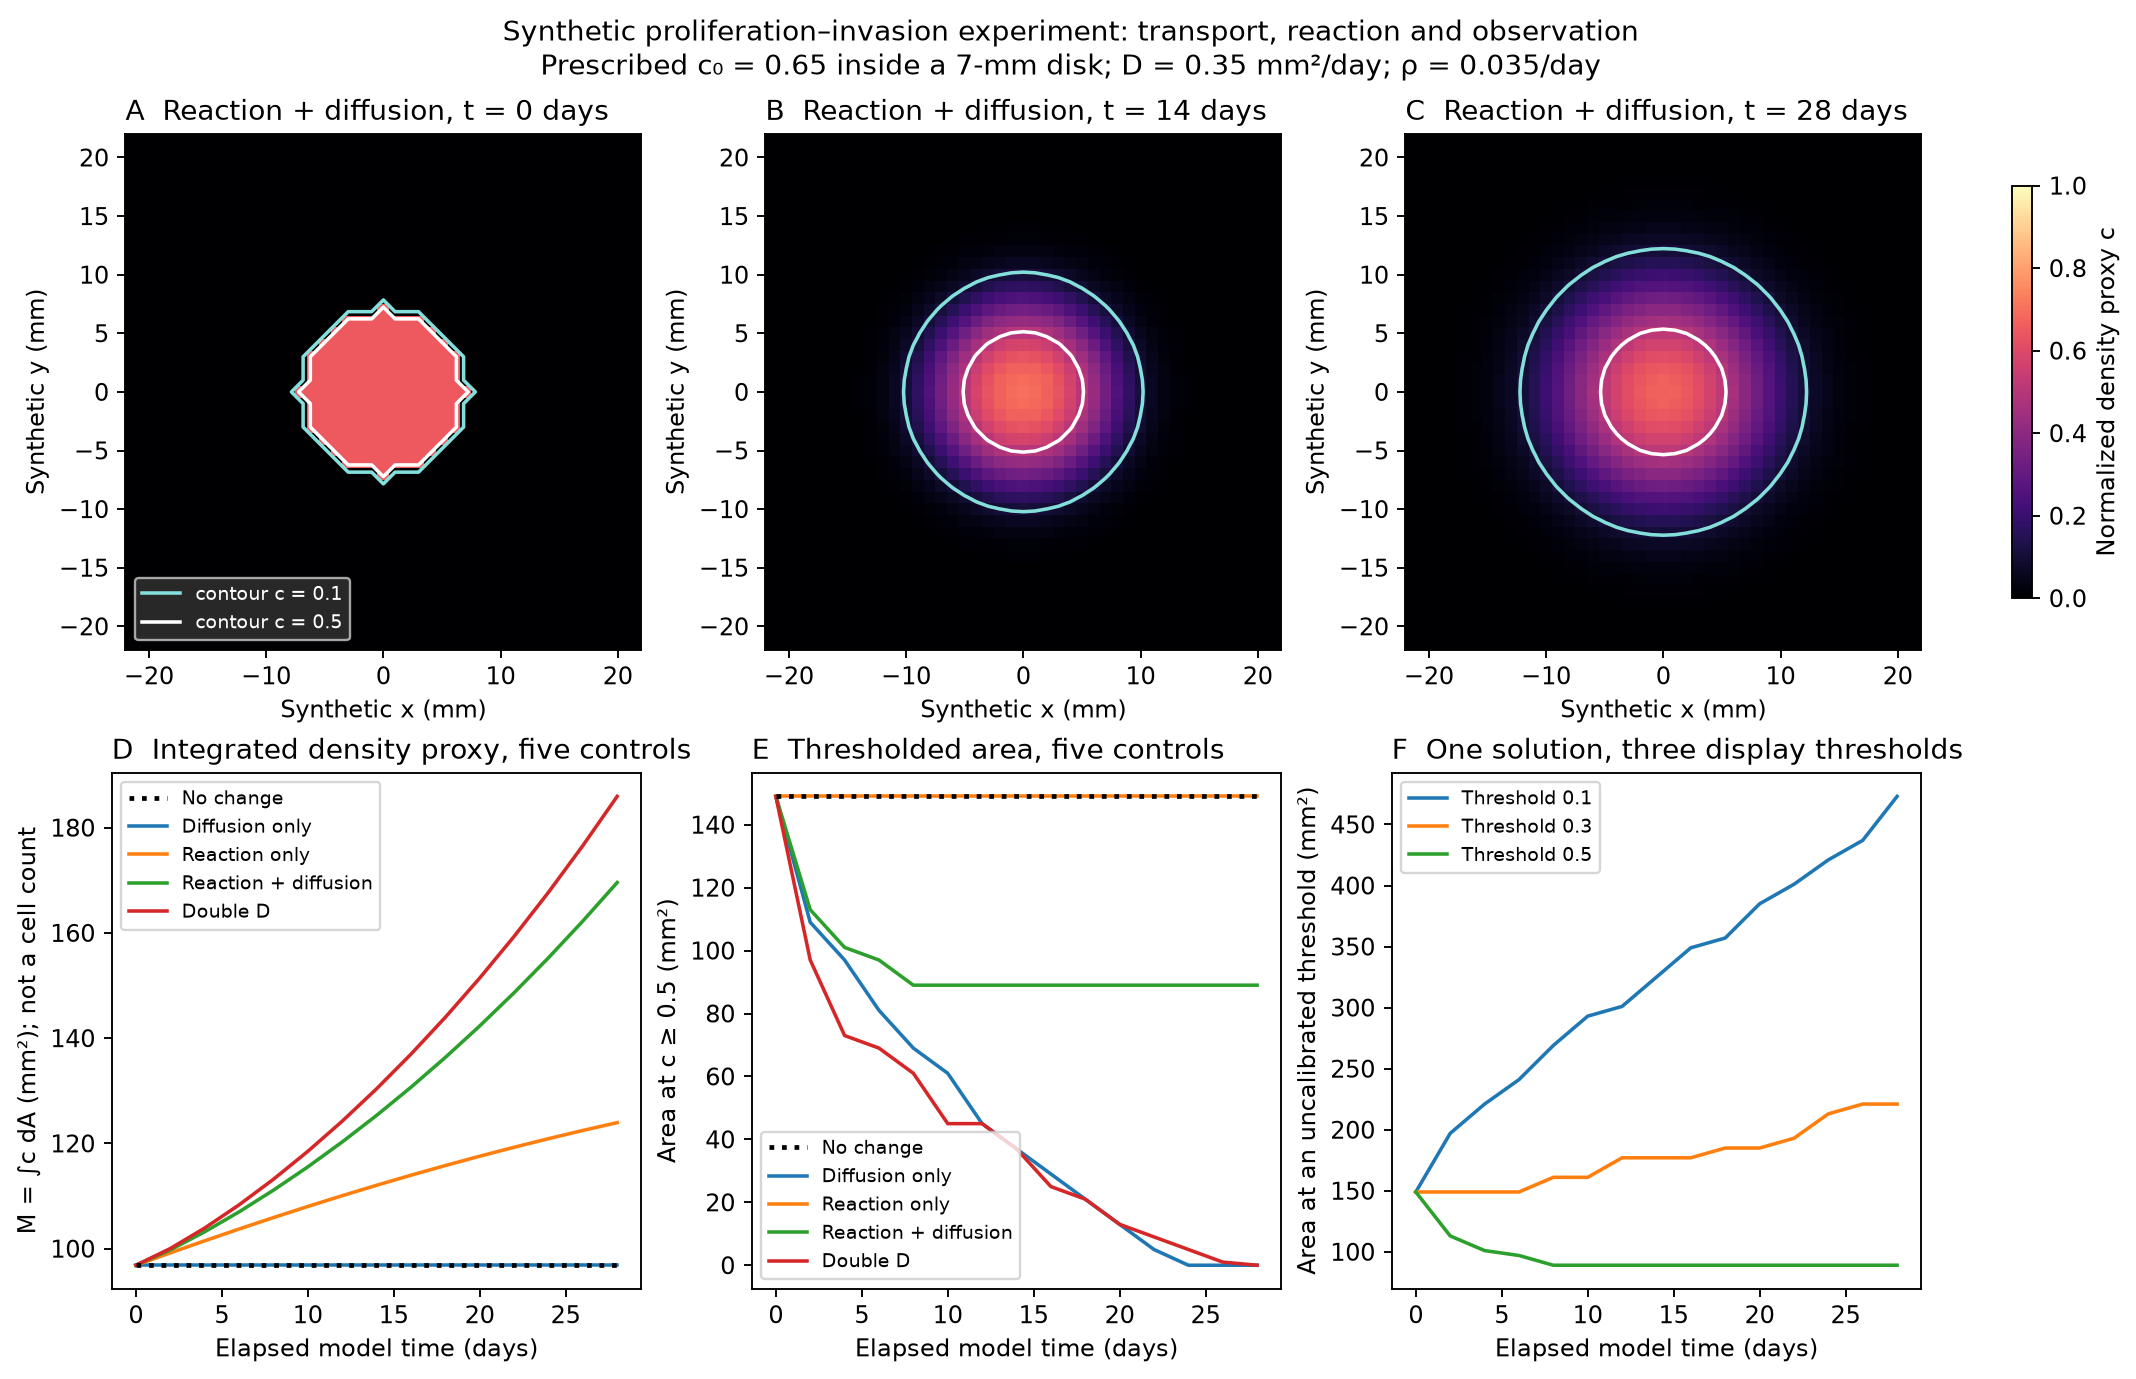

In [2]:
from glioma_ai.growth_examples import controls_animation, write_growth_experiment
from glioma_ai.growth_model import diffusion_step_limit, simulate_density_2d

output = ROOT / "outputs/notebook_02"
result = write_growth_experiment(output)
print(json.dumps(result["parameters"], indent=2))
print("Diffusion step bound (days):", diffusion_step_limit(0.35, 1.0, 1.0))
display(Image(filename=str(output / "growth_controls.png")))

**Figure 1. Migration, local growth and the choice of boundary change a simulated tumor in
different ways (synthetic construction).**
All panels solve $\partial_t c=\nabla\cdot(D\nabla c)+\rho c(1-c)$ on an 81 × 81 grid of
1 × 1 mm cells with no-flux outer boundaries. The initial state is $c_0=0.65$ inside a disk of
radius 7 mm (149 cells; the staircase edge is the 1-mm voxelization) and 0 outside. The state $c$
is a normalized density proxy, not MRI intensity, segmentation probability or a cell count.
**(A–C)** The reaction + diffusion model ($D=0.35$ mm²/day, $\rho=0.035$ day⁻¹) at 0, 14 and 28
days, on a fixed colour scale (magma, 0–1) and shown within ±22 mm of the centre. Cyan contour:
$c=0.1$; white contour: $c=0.5$. The low-density contour moves outward while the high-density
contour moves inward: migration spreads the tumor into a widening infiltrative margin faster than
local growth refills it. The peak density stays at or below 0.67, so saturation is not reached.
**(D)** Integrated density proxy $M=\int c\,dA$ (mm²) for five controls. No change (black dotted)
and diffusion only (blue) overlap at 96.9 mm², because no-flux diffusion only redistributes
density. Reaction only (orange) reaches 124.0 mm². Reaction + diffusion (green) reaches 169.6 mm²,
and doubling $D$ (red) reaches 185.9 mm². Migration increases total growth because spreading moves
density to where $c(1-c)$ is larger.
**(E)** Area above $c=0.5$ for the same controls. No change and reaction only overlap at 149 mm²:
reaction raises density inside the initial disk but cannot seed empty cells. Diffusion only and
double $D$ fall to 0 mm² by day 24–28. Reaction + diffusion settles at 89 mm², where local growth
balances dilution at the edge. Comparing D and E, the same run (red) has the largest $M$ yet no
area above 0.5.
**(F)** One solution (reaction + diffusion) read at three display thresholds. Over 28 days the
area grows from 149 to 473 mm² at $\theta=0.1$, to 221 mm² at $\theta=0.3$, and shrinks to
89 mm² at $\theta=0.5$. Read as a lesion size, the same simulated tumor would appear to more than
triple or to shrink by 40%, depending only on where the boundary is drawn.
Curves join 2-day snapshots; areas step in whole 1-mm² cells. The time step is at most 0.2 day,
below the stability bound for the largest $D$, and the discrete mass-balance residual is reported
by the next cell. Coefficients are prescribed, not fitted; their comparison with published patient
estimates is in the contribution record above. No patient data or trained model is involved.

### Explore Figure 1

The sliders re-solve the same disk experiment. Changing $D$ or $\rho$ re-runs the solver (well
under a second on a laptop CPU); moving the day or the threshold only selects a stored snapshot.
The ▶ button next to the day slider plays the chosen run forward in 2-day steps.
Things to try:
- Set $\rho=0$: $M$ stays constant while the $c=0.1$ contour moves outward, pure redistribution.
- Set $D=0$: the disk brightens but cannot grow beyond its initial support, however long you wait.
- Compare $D=0.6,\ \rho=0.02$ with $D=0.2,\ \rho=0.06$. Both have $D\rho=0.012$ and so the same
  theoretical speed $v_*$, but different front widths $\ell$ and different areas (Section 6).
- Move the threshold $\theta$ at a fixed day: the state is unchanged, only the "lesion size" is.

The explorer uses a 121 × 121 mm plane so that the front stays away from the outer no-flux wall
up to 100 days; the title warns if it does not. The sliders need a live kernel; a static rendering
stores only their initial view.

In [3]:
from glioma_ai.growth_interactive import isotropic_explorer

isotropic_explorer()

## 4. Read the controls before interpreting growth

- **No change:** checks the reference state.
- **Diffusion only:** checks that $M$ is conserved while boundaries move.
- **Reaction only:** increases density inside the existing support; it cannot seed a previously empty location.
- **Reaction + diffusion:** combines edge transport with local replenishment.
- **Double $D$:** changes transport with the same growth coefficient and initialization.

The animation below plays all five controls side by side on one colour scale, with $M$ in each
title. It needs no widgets, so it also plays in an exported or shared copy of the notebook. Watch
diffusion only spread while its $M$ stays at 96.85 mm², reaction only brighten without growing past
its initial edge, and double $D$ thin out fastest while gaining the most $M$.

Panel F changes the observation threshold while leaving the physical solution unchanged. Look for an increasing integrated proxy alongside a shrinking high-threshold area. That is a model behavior to understand, not evidence that a patient's tumor shrank.

In [4]:
for name, values in result["controls"].items():
    print(
        f"{name:22s} M: {values['initial_integral_mm2']:.2f} → "
        f"{values['final_integral_mm2']:.2f} mm²; "
        f"A(0.5): {values['final_area_threshold_05_mm2']:.1f} mm²"
    )
with np.load(output / "growth_snapshots.npz", allow_pickle=False) as arrays:
    names, days = arrays["control_names"].tolist(), arrays["days"].copy()
    controls = dict(zip(names, arrays["control_density"].copy(), strict=True))
    coordinates = arrays["x_mm"].copy()
display(HTML(controls_animation(controls, days, coordinates)))

No change              M: 96.85 → 96.85 mm²; A(0.5): 149.0 mm²
Diffusion only         M: 96.85 → 96.85 mm²; A(0.5): 0.0 mm²
Reaction only          M: 96.85 → 123.95 mm²; A(0.5): 149.0 mm²
Reaction + diffusion   M: 96.85 → 169.57 mm²; A(0.5): 89.0 mm²
Double D               M: 96.85 → 185.94 mm²; A(0.5): 0.0 mm²


## 5. Verify against independent mathematical answers

For spatially uniform $c_0$, diffusion vanishes and
$c(t)=[1+(c_0^{-1}-1)e^{-\rho t}]^{-1}$. The homogeneous test should match this formula to floating-point precision.

For $\rho=0$, even heterogeneous $D(x,y)$ must preserve total $M$ under no-flux boundaries. For a smooth independent benchmark on $[0,L]^2$, use

$$c(x,y,t)=0.4+0.2e^{-2D(\pi/L)^2t}\cos(\pi x/L)\cos(\pi y/L).$$

It has zero normal derivative on all four boundaries and satisfies the diffusion equation. The package tests 15×15, 30×30 and 60×60 cell-center grids with time steps proportional to $\Delta x^2$. This checks combined spatial/time error against an analytic solution. The separate time-step-halving check below uses the discontinuous tumor-like seed; its RMS difference is not a patient prediction error.

In [5]:
checks = result["analytic_verification"]
print(json.dumps(checks, indent=2))
assert checks["homogeneous_logistic_max_error"] < 1e-12
assert checks["heterogeneous_diffusion_mass_error_mm2"] < 1e-10
errors = [row["rms_error"] for row in checks["neumann_cosine_refinement"]]
assert errors[0] > errors[1] > errors[2]
assert result["binary_initialization_reaction_only_change"] == 0
print("Step-halving density RMS:", result["step_halving_density_rms"])
print(
    "Largest discrete balance residual (mm²):",
    max(v["max_balance_residual_mm2"] for v in result["controls"].values()),
)

try:
    simulate_density_2d(np.full((11, 11), 0.2), 1.0, 0.035, [0, 1], dt_days=0.3)
except ValueError as exc:
    print("Expected rejection:", exc)
else:
    raise AssertionError("An unstable step was accepted.")

{
  "homogeneous_logistic_max_error": 2.220446049250313e-16,
  "heterogeneous_diffusion_mass_error_mm2": 0.0,
  "neumann_cosine_refinement": [
    {
      "n": 15,
      "spacing_mm": 1.3333333333333333,
      "dt_days_max": 0.022222222222222223,
      "rms_error": 3.0696770751152706e-05
    },
    {
      "n": 30,
      "spacing_mm": 0.6666666666666666,
      "dt_days_max": 0.005555555555555556,
      "rms_error": 7.679599655363975e-06
    },
    {
      "n": 60,
      "spacing_mm": 0.3333333333333333,
      "dt_days_max": 0.001388888888888889,
      "rms_error": 1.9202376897204647e-06
    }
  ],
  "verification_scope": "analytic/numerical controls, not clinical validation"
}
Step-halving density RMS: 5.6478576203353094e-05
Largest discrete balance residual (mm²): 5.684341886080802e-14
Expected rejection: Time step 0.3 exceeds diffusion stability bound 0.25 days.


## 6. Why fitting a radius is not enough

Characteristic scales are $\ell=\sqrt{D/\rho}$ and $\tau=1/\rho$ when $\rho>0$. In the constant-medium planar Fisher equation, the minimal asymptotic traveling-wave speed is $v_*=2\sqrt{D\rho}$. This is a theoretical limit, **not** the speed of a finite curved mask edge or a measured MRI lesion.

Pairs $(D,\rho)$ with the same product have the same theoretical $v_*$ but different front widths and transient fields. A thresholded area, an unknown initial occupancy and two treated scans cannot generally identify both biological coefficients. Notebook 03 therefore compares prescribed scenarios without declaring a best patient fit.

For this example, $D=0.35$ mm²/day and $\rho=0.035$ day⁻¹ are prescribed inputs; the contribution record compares them with published patient estimates (Wang et al. 2009). There is no estimate of a patient's migration, proliferation, prognosis or treatment response.

## 7. Tissue-guided, anisotropic spread (Figure 2)

**Why anatomy.** In Figure 1 migration and growth are the same in every direction. A brain is not
like that: glioma cells migrate preferentially along white-matter tracts, and CSF spaces separate
tissue. Hannisdal et al. analysed 390 paired MRI examinations from 195 patients with grade 4 glioma
and classified primary and recurrent tumors by lobe
([npj Precis Oncol 2026](https://doi.org/10.1038/s41698-026-01557-0)). Most recurrences (68.7%)
stayed within the original lobe; 31.3% also appeared in new lobes, with migration strongest between
adjacent regions. Parietal tumors had the second-highest rate of recurrence in new sites (29.4%),
and the paper illustrates a parietal tumor whose recurrence appeared in the other hemisphere's
temporal lobe. The authors suggest that posterior white matter, including the splenium of the
corpus callosum, may facilitate migration, and note that differences in lobe size may also
contribute. Figure 2 poses the corresponding modelling question on a constructed slice: how do
grey/white contrast and fibre direction change where and when a left parietal tumor reaches the
other hemisphere?

**Model.** With a diagonal diffusion tensor $\mathbf D=\mathrm{diag}(D_{xx},D_{yy})$,

$$\frac{\partial c}{\partial t}=\frac{\partial}{\partial x}\!\left(D_{xx}\frac{\partial c}{\partial x}\right)
+\frac{\partial}{\partial y}\!\left(D_{yy}\frac{\partial c}{\partial y}\right)+\rho(x,y)\,c(1-c).$$

| Constructed tissue | $D_{xx}$ | $D_{yy}$ | $\rho$ |
|---|---|---|---|
| Grey matter (cortex, thalamus) | $D_g$ | $D_g$ | $\rho$ |
| White matter, no dominant direction | $rD_g$ | $rD_g$ | $\rho$ |
| Corpus callosum (left–right fibres) | $a\,rD_g$ | $rD_g$ | $\rho$ |
| Corona radiata (inferior–superior fibres) | $rD_g$ | $a\,rD_g$ | $\rho$ |
| CSF and outside the brain | 0 | 0 | 0 |

$r\ge1$ is the white/grey ratio and $a\ge1$ the along-fibre factor. Tissue-dependent diffusion was
introduced for gliomas by
[Swanson, Alvord & Murray (2000)](https://doi.org/10.1046/j.1365-2184.2000.00177.x); anisotropic
tensors derived from diffusion tensor imaging were used by
[Jbabdi et al. (2005)](https://doi.org/10.1002/mrm.20625),
[Clatz et al. (2005)](https://doi.org/10.1109/TMI.2005.857217) and
[Painter & Hillen (2013)](https://doi.org/10.1016/j.jtbi.2013.01.014). Here the directions are
prescribed by the phantom, not measured.

**Coordinates.** $x$ runs from the patient's right (negative) to left (positive) and $y$ from
inferior to superior, both in mm. Plotting $x$ to the right puts the patient's left on the viewer's
right, the radiological convention of clinical images. Every panel is labelled R and L.

**Numerics.** The coefficient on the face between two cells is the harmonic mean,
$D^x_{i+1/2,j}=2D^x_{ij}D^x_{i+1,j}/(D^x_{ij}+D^x_{i+1,j})$, which is zero if either cell has
$D=0$, so no density crosses into CSF. (The arithmetic mean of Section 3 would let density leak
into $D=0$ cells.) The diffusion update is a convex combination, and so keeps $0\le c\le1$, when

$$h\le\Big[\max_{ij}\Big(\frac{D^x_{i-1/2,j}+D^x_{i+1/2,j}}{\Delta x^2}
+\frac{D^y_{i,j-1/2}+D^y_{i,j+1/2}}{\Delta y^2}\Big)\Big]^{-1}.$$

The runs use 0.9 of this limit, capped at 0.2 day; larger steps are rejected, never clipped.
Reaction is the exact logistic flow with $\rho(x,y)$, as in Section 3.

**Three nested assumptions** switch on one tissue effect at a time: uniform tissue ($r=a=1$, so
$D_g$ everywhere in brain), grey/white contrast ($r=5$, $a=1$), and contrast plus fibre anisotropy
($r=5$, $a=2$). The uniform case is slower overall; it is not a matched-mean control.

{
  "kind": "constructed coronal slice; not an atlas, image or segmentation",
  "shape": [
    141,
    111
  ],
  "spacing_mm": 1.0,
  "x_axis": "patient right (negative) to patient left (positive)",
  "y_axis": "inferior (negative) to superior (positive)",
  "tissue_cells": {
    "outside brain": 4562,
    "CSF": 1582,
    "grey matter": 2207,
    "white matter": 7300
  },
  "fibre_cells": {
    "no dominant direction": 12704,
    "left-right (callosal)": 595,
    "inferior-superior (projection)": 2352
  }
}
Uniform tissue, isotropic                first c ≥ 0.1 across midline: not reached; contralateral share 0.0% (240 d), 0.1% (365 d); step 0.2 day
Grey/white contrast, isotropic           first c ≥ 0.1 across midline: day 190; contralateral share 1.5% (240 d), 15.1% (365 d); step 0.2 day
Grey/white contrast + fibre anisotropy   first c ≥ 0.1 across midline: day 170; contralateral share 3.4% (240 d), 24.3% (365 d); step 0.2 day
Anisotropic cosine-mode RMS errors (15, 30, 60 cells): 

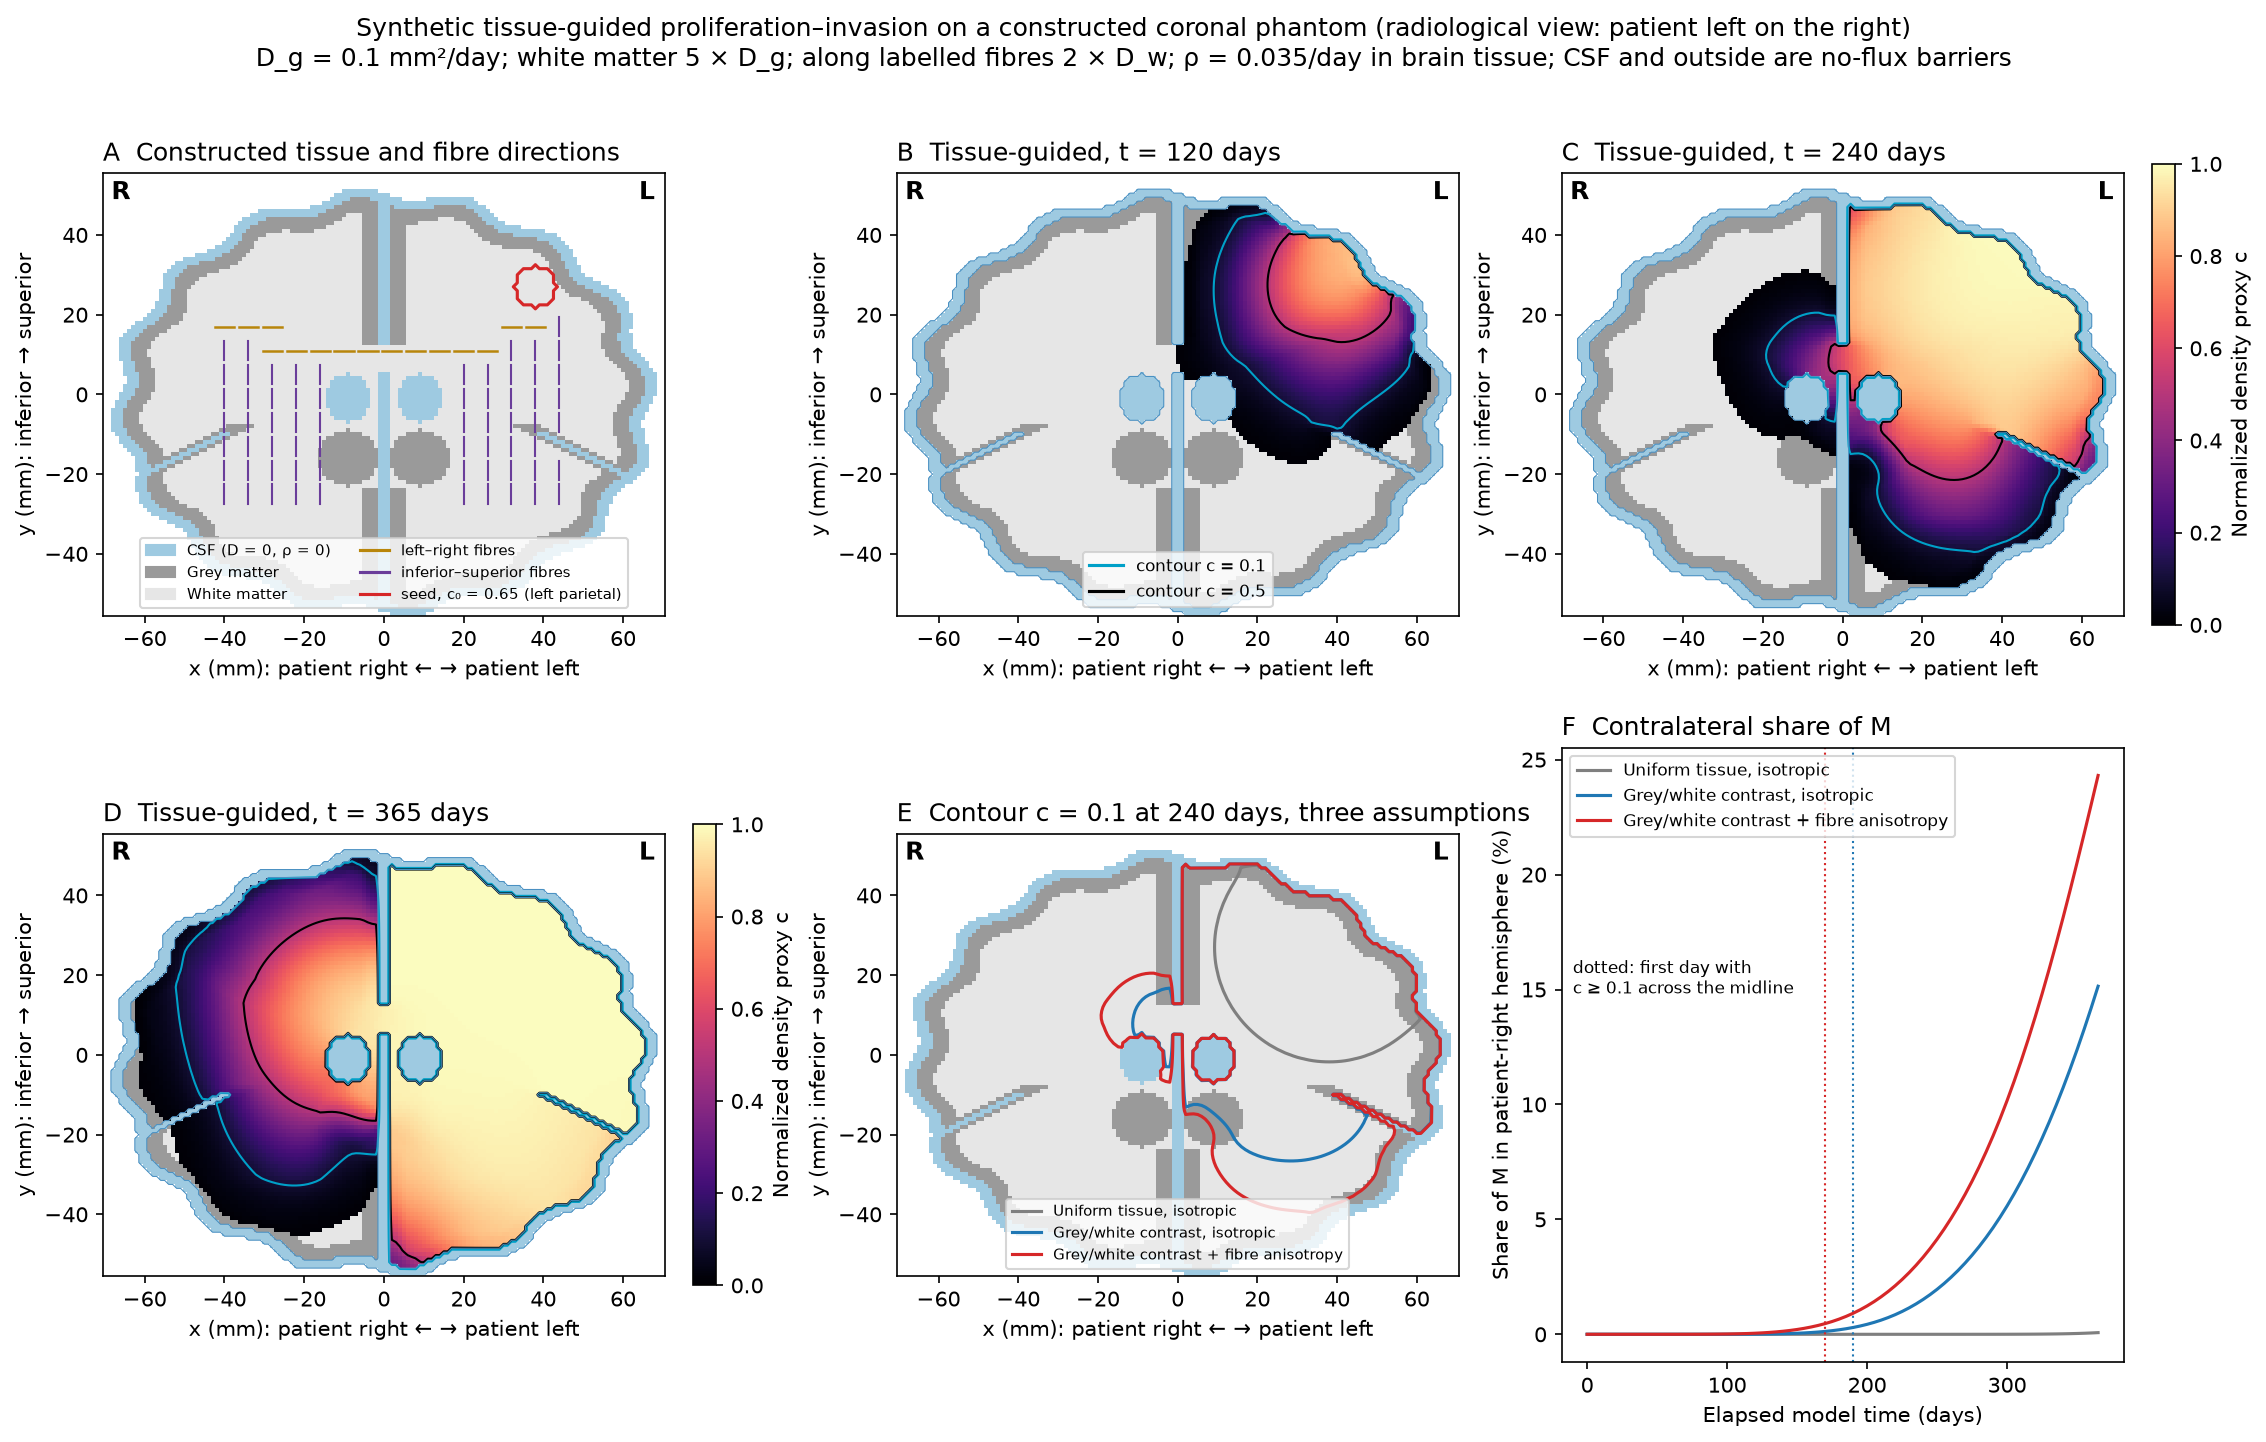

In [6]:
from glioma_ai.growth_examples import write_tissue_experiment

tissue = write_tissue_experiment(output)
print(json.dumps(tissue["phantom"], indent=2))
for name, values in tissue["scenarios"].items():
    first = values["first_day_c_ge_0.1_across_midline"]
    print(
        f"{name:40s} first c ≥ 0.1 across midline: "
        f"{'not reached' if first is None else f'day {first:g}'}; contralateral share "
        f"{100 * values['contralateral_share_day_240']:.1f}% (240 d), "
        f"{100 * values['contralateral_share_day_365']:.1f}% (365 d); "
        f"step {values['dt_days']:.3g} day"
    )
tissue_checks = tissue["verification"]
assert tissue_checks["isotropic_reduction_max_difference"] < 1e-13
assert tissue_checks["barrier_cells_max_density"] == 0
assert tissue_checks["heterogeneous_anisotropic_mass_error_mm2"] < 1e-10
errors = [row["rms_error"] for row in tissue_checks["anisotropic_cosine_refinement"]]
assert errors[0] > errors[1] > errors[2]
print("Anisotropic cosine-mode RMS errors (15, 30, 60 cells):", errors)
display(Image(filename=str(output / "tissue_growth.png")))

**Figure 2. Grey/white contrast and fibre direction steer a simulated left parietal tumor
across the corpus callosum (synthetic construction).**
All panels solve the tissue-guided equation above on a constructed 141 × 111 grid of
1 × 1 mm cells (a coronal slice at roughly callosal level), in radiological view (patient left on
the viewer's right). **(A)** The phantom: CSF (blue; subarachnoid rim, interhemispheric fissure,
lateral ventricles, Sylvian fissures and a midline barrier below the callosum), grey matter (dark
grey; cortex and thalamus) and white matter (light grey). Short lines mark the prescribed fibre
directions, left–right in the corpus callosum (ochre) and inferior–superior in the corona radiata
(purple). The hemispheres connect only through the corpus callosum. Red contour: the seed,
$c_0=0.65$ in a 5-mm-radius disk of left parietal white matter (81 cells) touching the lateral
callosal radiation.
**(B–D)** The tissue-guided run ($D_g=0.1$, $D_w=0.5$ and 1.0 mm²/day along fibres;
$\rho=0.035$ day⁻¹) at 120, 240 and 365 days. Blue contour: $c=0.1$; black: $c=0.5$. At 120 days
the infiltrative margin has spread through left white matter but remains in the left hemisphere.
By 240 days it has crossed the corpus callosum and is spreading through right white matter around
the ventricles. At 365 days the left hemisphere is close to saturation and the right is widely
infiltrated. Grey matter slows the front and the CSF walls shape it.
**(E)** The $c=0.1$ contour at 240 days under three nested assumptions: uniform tissue (grey;
$D_g$ everywhere), grey/white contrast (blue; $r=5$) and contrast plus fibre anisotropy (red;
$r=5$, $a=2$). With uniform tissue the tumor stays local; contrast carries it to and just across
the callosum; anisotropy carries it further.
**(F)** Share of the integrated density proxy $M$ in the patient's right hemisphere. A density of
at least 0.1 first crosses the midline at day 190 with contrast alone and at day 170 with
anisotropy, and not within the year with uniform tissue. At 365 days the share is 15.1% and 24.3%,
against 0.07% for uniform tissue.
Snapshots every 5 days; the 0.2-day steps are below each run's positivity limit, and the
mass-balance residuals are reported by the cell above. Coefficients are prescribed teaching
values, not fitted; nothing here predicts where a patient's tumor will recur.

### Explore Figure 2

The sliders set $D_g$, the white/grey ratio $r$, the along-fibre factor $a$, $\rho$ and the day.
Each coefficient change re-solves the three nested runs (about 0.5–1.5 s on a laptop CPU), and
▶ plays the year in 5-day steps. Left:
the tissue-guided run; middle: uniform tissue at the same day; right: the contralateral share over
the year, with each run's first crossing day in the legend. Things to try:
- Raise $a$ from 1 to 4: how much earlier is the crossing, and how much does the left hemisphere
  change?
- Set $r=1$ and $a=1$: the tissue-guided and uniform panels become identical.
- Raise $\rho$ with $D_g$ fixed: the front moves faster and the $c=0.5$ region fills in behind it.
- Compare pairs $(D_g,\rho)$ with the same product, as in Section 6.

In [7]:
from glioma_ai.growth_interactive import tissue_explorer

tissue_explorer()

**What Figure 2 does and does not show.**
- It shows how prescribed tissue contrast, fibre direction and CSF walls change the path and
  timing of a modelled front, with everything else held fixed.
- It does not represent a patient, an atlas or a registered image. The slice, fibre directions and
  coefficients are constructed. Real callosal fibres fan out at many angles, and a single 2D slice
  drops routes that leave the plane, such as other commissures.
- CSF is treated as a barrier, so spread along the ventricles or meninges is excluded.
- Crossing days and contralateral shares are properties of these assumptions. They are not
  recurrence predictions and do not test the lobe-level findings of Hannisdal et al. (2026); that
  would need real anatomy, measured diffusion directions, surgery and treatment, and patient
  follow-up. Notebook 03 takes the first of these steps with real structural MRI.

## 8. Controlled extensions

1. Change one prescribed coefficient, retain the other assumptions and inspect both $M$ and $A_\theta$.
2. Use `simulate_density_2d` with a **constructed** spatial $D$ field. Check conservation at $\rho=0$ before interpreting asymmetric migration. Do not infer white matter from CT1 intensity. Section 7 does this with `simulate_tissue_density_2d`; move the seed with `tumour_seed(phantom, centre_mm=(x, y))` closer to or further from the callosum and compare crossing days.
3. Repeat with initial occupancy 0.55, 0.65 and 1.0. Explain why the binary reaction-only control cannot expand.
4. Continue to [03_lumiere_prepared_slice.ipynb](03_lumiere_prepared_slice.ipynb): a real structural ROI replaces the disk; none of the hidden-state assumptions becomes measured merely because anatomy is real.

The biological route then connects to cell-state transitions (08), astrocytic potassium handling (10), the cautious field/cognition discussion (11), and slow activity-associated growth feedback (09). These are different levels of explanation, not a validated chain from a modeled tumor boundary to cognition.

**Reproducibility:** JSON parameters, analytic checks, PNG/PDF panels, snapshot NPZ and source/environment/output hashes are saved in ignored `outputs/notebook_02/`. Figure 2 adds `tissue_growth.{png,pdf,json}` and `tissue_growth_run.json`. Rebuilding is deterministic and calls no language model.